# 第 4 章 让电脑玩掷骰子：生成随机数 —— 代码实现

对应笔记 `docs/mc/ch04.md`。六个实验：平方取中、手写 MINSTD 线性同余、RANDU 的三维露饴、卡方/KS 统计检验、不均匀骰子（查表法）、泊松分布（Knuth 乘积法）。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch04")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2027)

## 4.1 平方取中：冯·诺依曼的失败方案

取 $2d$ 位平方的中间 $d$ 位作下一个“随机数”。两个死穴：掉进 0 后永远出不来；周期极短。

In [2]:
def middle_square(seed, digits=4, n=25):
    x, out = seed, []
    for _ in range(n):
        s = f"{x*x:0{2*digits}d}"
        x = int(s[digits//2 : digits//2 + digits])
        out.append(x)
    return out

print("种子 4353:", middle_square(4353, n=12))
print("种子 1000:", middle_square(1000, n=6), "← 掉进 0 出不来")
seq = middle_square(3792, n=60)
uniq_until_repeat = len(np.unique(seq))
print(f"种子 3792：60 步里只有 {uniq_until_repeat} 个不同值（周期 ≤ {uniq_until_repeat}）")

种子 4353: [9486, 9841, 8452, 4363, 357, 1274, 6230, 8129, 806, 6496, 1980, 9204]
种子 1000: [0, 0, 0, 0, 0, 0] ← 掉进 0 出不来
种子 3792：60 步里只有 1 个不同值（周期 ≤ 1）


## 4.2 手写线性同余：MINSTD（Park–Miller）

$X_{k+1} = aX_k \bmod m$，$a=16807$，$m=2^{31}-1$（素数）。归一化 $U_k = X_k/m \in (0,1)$。

均值 0.5000（理论 0.5），方差 0.08337（理论 0.08333）


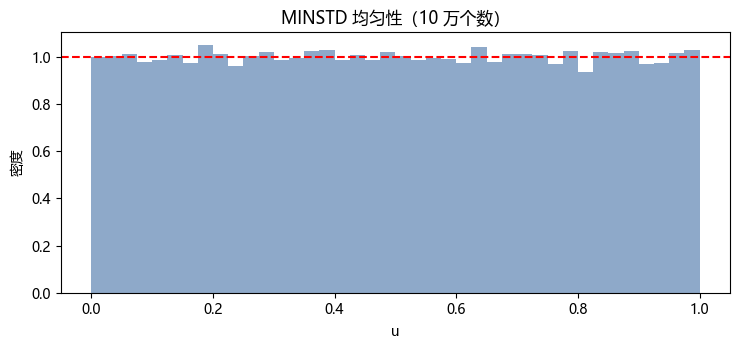

In [3]:
def minstd(n, seed=12345):
    m, a = 2**31 - 1, 16807
    x, out = seed, np.empty(n)
    for i in range(n):
        x = (a * x) % m
        out[i] = x / m
    return out

u = minstd(100_000)
print(f"均值 {u.mean():.4f}（理论 0.5），方差 {u.var():.5f}（理论 {1/12:.5f}）")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(u, bins=40, density=True, color="#8ea9c9")
ax.axhline(1.0, color="r", ls="--", lw=1.5)
ax.set(xlabel="u", ylabel="密度", title="MINSTD 均匀性（10 万个数）")
fig.tight_layout(); save(fig, "out-minstd.png"); plt.show()

## 4.2 谱结构：RANDU 在三维露饴

RANDU（$a=65539, m=2^{31}$）在二维散点图上看不出问题，把 $(X_k, X_{k+1}, X_{k+2})$ 当三维坐标画出来——只有 15 个平面。对比 MINSTD。

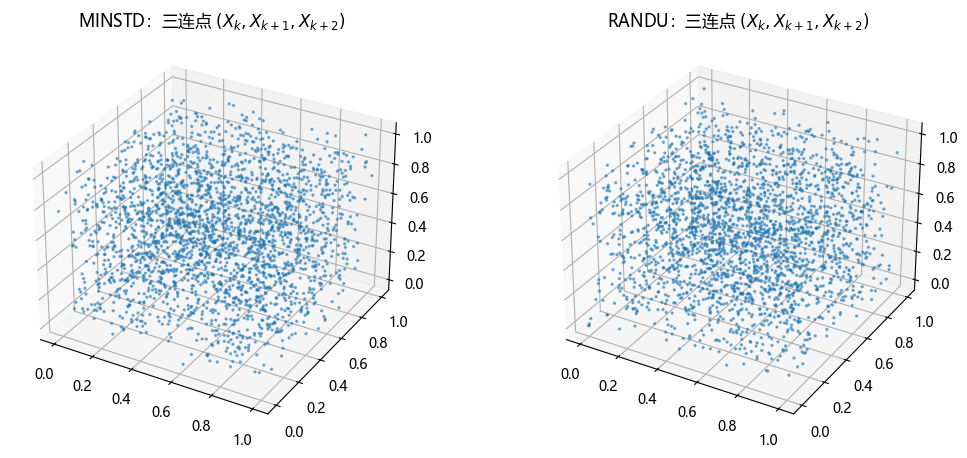

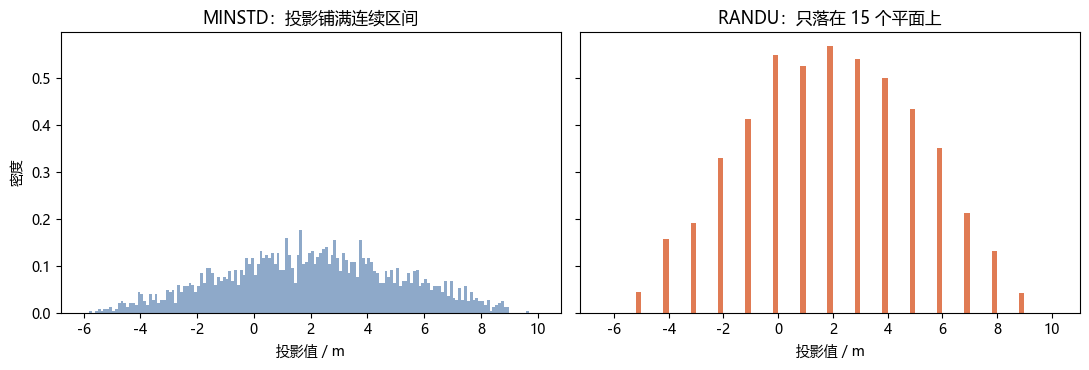

In [10]:
def lcg(n, a, m, seed=1):
    x, out = seed, np.empty((n, 3))
    for i in range(n):
        x = (a * x) % m
        out[i] = x / m
    return out

n = 2500
u_min = lcg(n + 2, 16807, 2**31 - 1)
u_ran = lcg(n + 2, 65539, 2**31)

fig = plt.figure(figsize=(11, 4.6))
for k, (u, name) in enumerate([(u_min, "MINSTD"), (u_ran, "RANDU")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(u[:-2, 0], u[1:-1, 0], u[2:, 0], s=2, alpha=0.5)
    ax.set_title(f"{name}：三连点 $(X_k, X_{{k+1}}, X_{{k+2}})$")
fig.tight_layout(); save(fig, "out-lattice.png"); plt.show()

# 投影实锤：RANDU 满足 9X_k − 6X_{k+1} + X_{k+2} ≡ 0 (mod 2³¹)
# → 投影值只能取 c ∈ {−5,…,9} 共 15 个平面；MINSTD 则铺满连续区间
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
proj_min = 9*u_min[:-2, 0] - 6*u_min[1:-1, 0] + u_min[2:, 0]
proj_ran = 9*u_ran[:-2, 0] - 6*u_ran[1:-1, 0] + u_ran[2:, 0]
axes[0].hist(proj_min, bins=160, range=(-6, 10), density=True, color="#8ea9c9")
axes[0].set(title="MINSTD：投影铺满连续区间", xlabel="投影值 / m", ylabel="密度")
axes[1].hist(proj_ran, bins=np.arange(-6.4, 10.4, 0.2), density=True, color="#e07b54")
axes[1].set(title="RANDU：只落在 15 个平面上", xlabel="投影值 / m",
            xticks=range(-6, 11, 2))
fig.tight_layout(); save(fig, "out-lattice-proj.png"); plt.show()

## 4.3 统计检验：卡方 + KS（顺带复习假设检验）

对三组数各跑均匀性检验：卡方（分组频数 vs 期望）与 KS（经验 CDF vs 理论 CDF）。RANDU 会教我们重要一课：**基本检验查不出好伪装的坏生成器**。

In [5]:
def uniform_tests(u, name, bins=20):
    cnt = np.histogram(u, bins=bins, range=(0, 1))[0]
    _, p_chi = stats.chisquare(cnt)                    # 拟合优度：均匀为原假设
    _, p_ks = stats.kstest(u, "uniform")              # KS：经验 CDF vs U(0,1)
    print(f"{name:>8}: 卡方 p = {p_chi:.3f}, KS p = {p_ks:.3f}")

uniform_tests(minstd(10_000, seed=123), "MINSTD")
uniform_tests(lcg(10_000, 65539, 2**31, seed=1)[:, 0], "RANDU")
uniform_tests(rng.random(10_000), "PCG64")
print("p 值小（如 < 0.05）= 与均匀性显著矛盾；p 大 = 没查出问题（≠ 证明了随机）")

  MINSTD: 卡方 p = 0.094, KS p = 0.152
   RANDU: 卡方 p = 0.712, KS p = 0.811
   PCG64: 卡方 p = 0.924, KS p = 0.573
p 值小（如 < 0.05）= 与均匀性显著矛盾；p 大 = 没查出问题（≠ 证明了随机）


## 4.5 离散分布：查表法（逆 CDF 的离散版）

不均匀骰子 $P(i)\propto i$（即 $1/21,\dots,6/21$）：累积概率表 + `searchsorted` 落表。

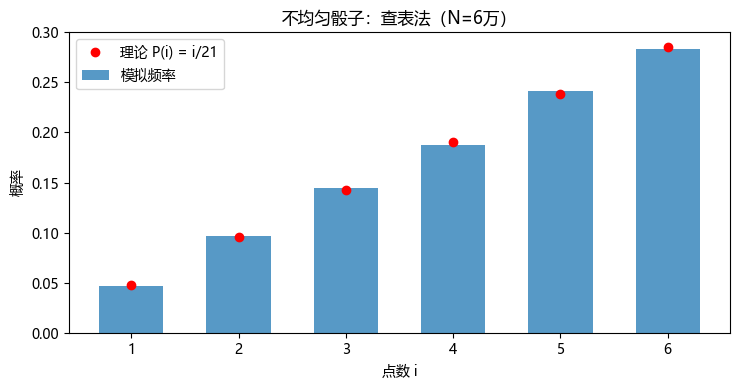

最大偏差: 0.0033880952380952456


In [6]:
p = np.arange(1, 7) / 21            # 1/21, ..., 6/21
cdf = np.cumsum(p)                  # 累积概率表
u = rng.random(60_000)
faces = np.searchsorted(cdf, u) + 1 # u 落在哪一段 → 哪个面

vals, cnts = np.unique(faces, return_counts=True)
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(vals, cnts / 60_000, width=0.6, alpha=0.75, label="模拟频率")
ax.plot(vals, p, "ro", ms=6, label="理论 P(i) = i/21")
ax.set(xlabel="点数 i", ylabel="概率", title="不均匀骰子：查表法（N=6万）")
ax.legend(); fig.tight_layout(); save(fig, "out-discrete.png"); plt.show()
print("最大偏差:", np.abs(cnts / 60_000 - p).max())

## 4.5 泊松分布：Knuth 乘积法

$-\ln U \sim Exp(1)$（2.5 节变换），不断连乘 $U$ 直到乘积第一次 $\le e^{-\lambda}$，计数即泊松样本（推导见笔记）。$\lambda=4$，与 NumPy 官方抽样对照。

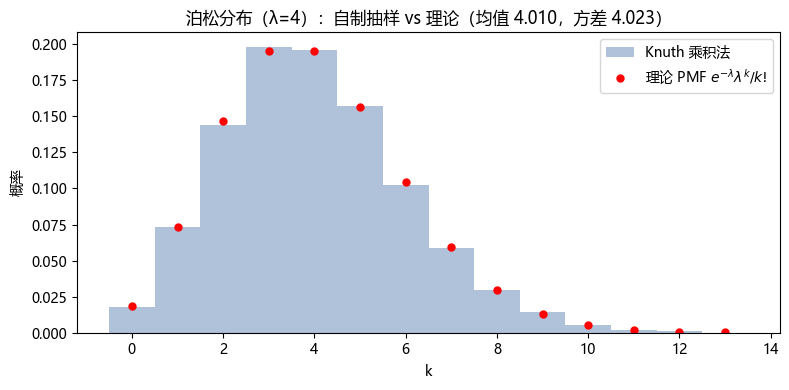

In [7]:
def poisson_knuth(lam):
    L = np.exp(-lam)
    k, prod = 0, rng.random()
    while prod > L:
        k += 1
        prod *= rng.random()
    return k

lam, reps = 4, 20_000
mine = np.array([poisson_knuth(lam) for _ in range(reps)])

ks = np.arange(0, 14)
pmf = stats.poisson.pmf(ks, lam)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(mine, bins=np.arange(-0.5, 14.5), density=True, alpha=0.7, color="#8ea9c9",
        label="Knuth 乘积法")
ax.plot(ks, pmf, "ro", ms=5, label=r"理论 PMF $e^{-\lambda}\lambda^k/k!$")
ax.set(xlabel="k", ylabel="概率",
       title=f"泊松分布（λ={lam}）：自制抽样 vs 理论（均值 {mine.mean():.3f}，方差 {mine.var():.3f}）")
ax.legend(); fig.tight_layout(); save(fig, "out-poisson.png"); plt.show()